# Analisis Tren

Nama: Irgi

## Import Library dan Load Data

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path

TICKERS = ['BBCA', 'BBRI', 'BMRI', 'BBNI']
NAMA_BANK = {
    'BBCA': 'Bank Central Asia',
    'BBRI': 'Bank Rakyat Indonesia',
    'BMRI': 'Bank Mandiri',
    'BBNI': 'Bank Negara Indonesia',
}
WARNA = {'BBCA': '#2a78d6', 'BBRI': '#eb6834', 'BMRI': '#1baf7a', 'BBNI': '#eda100'}

# lokasi folder dataset (root repo / folder kerja), kalau tidak ada ambil dari GitHub
if Path('dataset').is_dir():
    ROOT = Path('.')
elif Path('../dataset').is_dir():
    ROOT = Path('..')
else:
    ROOT = None
DATA_DIR = f'{ROOT}/dataset' if ROOT else 'https://raw.githubusercontent.com/aprilianza/Midterm_DataVisualization/main/dataset'
FIG_DIR = (ROOT or Path('.')) / 'figures'
FIG_DIR.mkdir(exist_ok=True)

list_df = []
for t in TICKERS:
    df = pd.read_csv(f'{DATA_DIR}/{t}.JK_10_years.csv')
    df['Date'] = pd.to_datetime(df['Date'], utc=True).dt.tz_localize(None)
    df['Ticker'] = t
    list_df.append(df.sort_values('Date'))

df_all = pd.concat(list_df, ignore_index=True)
df_all = df_all[['Date', 'Ticker', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']]
df_all = df_all.drop_duplicates(['Ticker', 'Date'])

# baris volume 0 dengan harga datar = hari libur bursa, dibuang untuk semua bank
libur = ((df_all['Volume'] == 0) & (df_all['Open'] == df_all['Close'])
         & (df_all['High'] == df_all['Close']) & (df_all['Low'] == df_all['Close']))
HARI_DIBUANG = pd.DatetimeIndex(df_all.loc[libur, 'Date'].unique()).sort_values()
df_all = df_all[~df_all['Date'].isin(HARI_DIBUANG)].reset_index(drop=True)

adj_wide = df_all.pivot(index='Date', columns='Ticker', values='Adj Close')[TICKERS]
vol_wide = df_all.pivot(index='Date', columns='Ticker', values='Volume')[TICKERS]

plt.rcParams.update({
    'figure.figsize': (12, 5),
    'savefig.dpi': 200,
    'savefig.bbox': 'tight',
    'font.size': 11,
    'axes.titlesize': 14,
    'axes.titleweight': 'bold',
    'axes.titlelocation': 'left',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.color': '#e6e5e0',
    'legend.frameon': False,
})


def simpan_fig(fig, nama):
    fig.savefig(FIG_DIR / f'{nama}.png')


def format_tanggal(ax):
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))


print('Jumlah baris df_all :', len(df_all))
print('Rentang tanggal     :', df_all['Date'].min().date(), 's.d.', df_all['Date'].max().date())
print('Hari libur dibuang  :', len(HARI_DIBUANG))

Jumlah baris df_all : 9616
Rentang tanggal     : 2014-12-08 s.d. 2024-12-03
Hari libur dibuang  : 69


## Moving Average

Moving average menghitung rata-rata harga pada jendela (window) waktu tertentu untuk memperhalus fluktuasi harian dan memperjelas arah tren jangka panjang. Tiga ukuran window digunakan:
- MA-20 (20-day average): mencakup 20 hari bursa (sekitar 1 bulan kalender), paling responsif terhadap pembalikan arah harga namun masih sensitif terhadap fluktuasi jangka pendek.
- MA-50 (50-day average): mencakup 50 hari bursa (sekitar 2,5 bulan kalender), menyeimbangkan kehalusan kurva dan kecepatan reaksi terhadap perubahan tren.
- MA-100 (100-day average): mencakup 100 hari bursa (sekitar 5 bulan kalender), menghasilkan kurva yang sangat halus untuk memetakan tren jangka menengah-panjang.

Trade-off NaN: Perhitungan window sebesar *n* membutuhkan minimal *n* data historis. Akibatnya, sebanyak *n* - 1 baris pertama pada deret waktu bernilai NaN (tidak terdefinisi). MA-20 kehilangan 19 hari pertama, MA-50 kehilangan 49 hari pertama, dan MA-100 kehilangan 99 hari pertama. Semakin besar ukuran window, semakin bersih kurva dari noise, namun semakin banyak data awal yang terpotong serta semakin lambat kurva bereaksi (lagging) terhadap momentum pergerakan harga terkini.

Trade-off NaN pada deret waktu:
  MA-20  (20-day)  : 19 baris awal bernilai NaN
  MA-50  (50-day)  : 49 baris awal bernilai NaN
  MA-100 (100-day) : 99 baris awal bernilai NaN


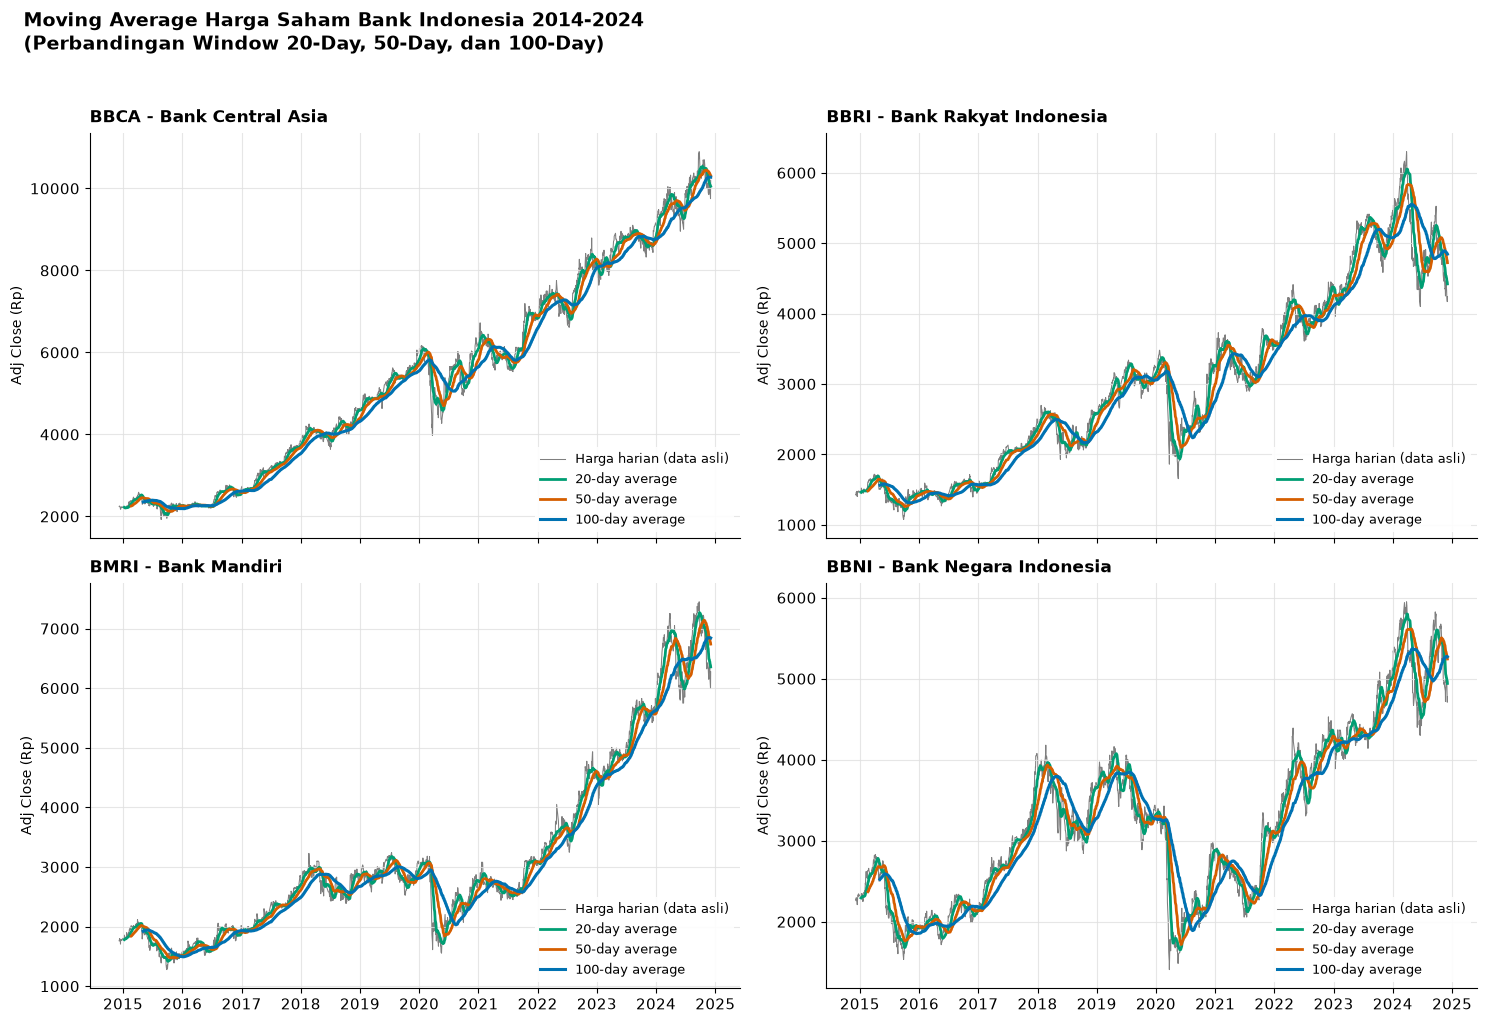

In [12]:
# Parameter window
D_WINDOW_PENDEK = 20
D_WINDOW_MENENGAH = 50
D_WINDOW_PANJANG = 100

# Hitung Moving Average untuk semua bank
d_ma20 = adj_wide.rolling(D_WINDOW_PENDEK).mean()
d_ma50 = adj_wide.rolling(D_WINDOW_MENENGAH).mean()
d_ma100 = adj_wide.rolling(D_WINDOW_PANJANG).mean()

# Informasi trade-off NaN per window
print('Trade-off NaN pada deret waktu:')
print(f'  MA-{D_WINDOW_PENDEK}  (20-day)  : {D_WINDOW_PENDEK - 1} baris awal bernilai NaN')
print(f'  MA-{D_WINDOW_MENENGAH}  (50-day)  : {D_WINDOW_MENENGAH - 1} baris awal bernilai NaN')
print(f'  MA-{D_WINDOW_PANJANG} (100-day) : {D_WINDOW_PANJANG - 1} baris awal bernilai NaN')

D_C_RAW = '#000000'   # hitam tipis untuk data harian asli
D_C_MA20 = '#009E73'   # hijau teal
D_C_MA50 = '#D55E00'   # oranye vermilion
D_C_MA100 = '#0072B2'  # biru kuat

# Visualisasi
fig, axes = plt.subplots(2, 2, figsize=(15, 10), sharex=True)
axes = axes.flatten()
for idx, ticker in enumerate(TICKERS):
    ax = axes[idx]
    ax.plot(adj_wide.index, adj_wide[ticker],
            color=D_C_RAW, alpha=0.50, linewidth=0.75,
            label='Harga harian (data asli)', zorder=1)
    ax.plot(d_ma20.index, d_ma20[ticker],
            color=D_C_MA20, linewidth=2.0,
            label=f'{D_WINDOW_PENDEK}-day average', zorder=3)
    ax.plot(d_ma50.index, d_ma50[ticker],
            color=D_C_MA50, linewidth=2.0,
            label=f'{D_WINDOW_MENENGAH}-day average', zorder=4)
    ax.plot(d_ma100.index, d_ma100[ticker],
            color=D_C_MA100, linewidth=2.2,
            label=f'{D_WINDOW_PANJANG}-day average', zorder=5)
    ax.set_title(f'{ticker} - {NAMA_BANK[ticker]}', fontsize=12, fontweight='bold', pad=8)
    ax.set_ylabel('Adj Close (Rp)', fontsize=10)
    format_tanggal(ax)
    ax.grid(True, linestyle='-', color='#e0e0e0', linewidth=0.8, alpha=0.8)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.legend(loc='lower right', fontsize=9, frameon=True,
              facecolor='white', framealpha=0.9, edgecolor='none')
fig.suptitle(
    'Moving Average Harga Saham Bank Indonesia 2014-2024\n'
    '(Perbandingan Window 20-Day, 50-Day, dan 100-Day)',
    fontsize=14, fontweight='bold', x=0.02, ha='left', y=1.02
)
fig.tight_layout()
simpan_fig(fig, '05a_moving_average')
plt.show()

**Insight:** MA-20 (hijau) bereaksi paling cepat terhadap fluktuasi harga harian dan penurunan mendadak saat awal pandemi COVID-19 (Maret 2020), sedangkan MA-100 (biru) memperlihatkan arah tren sekuler jangka panjang yang jauh lebih stabil dan tahan terhadap noise. Saham BBCA dan BMRI menunjukkan tren naik paling konsisten sepanjang 2014-2024 dengan kurva MA-100 yang menanjak pada 79% (BBCA) dan 73% (BMRI) hari pengamatan, dibanding 66% (BBRI) dan 63% (BBNI). BBRI mengalami koreksi tren yang cukup dalam pada 2024 (dari puncak Rp6.300 pada Maret 2024 ke Rp4.240 di akhir data), sedangkan BBNI cenderung turun pada rentang 2018-2021 (sekitar -24%) dengan rentang harga hampir 3×.

#### Detail Trade-off Window pada BBCA

Grafik berikut memperbesar saham BBCA (Bank Central Asia) untuk mengilustrasikan trade-off antara responsivitas kurva, kehalusan data, serta area data awal yang hilang (NaN) pada MA-100.

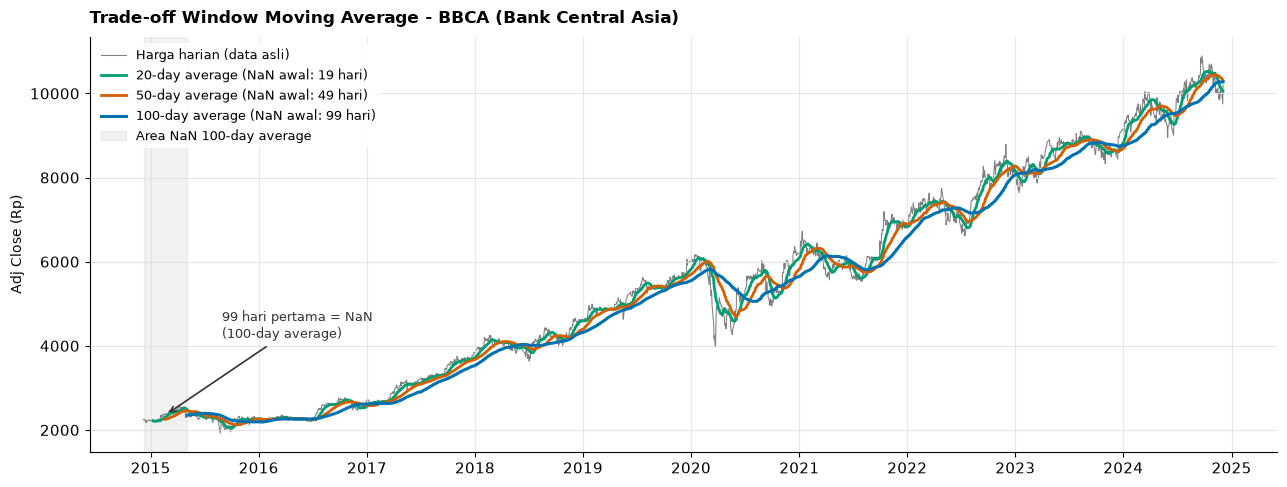

In [13]:
# Ilustrasi detail trade-off window dan area NaN pada BBCA
d_ticker_detail = 'BBCA'
d_seri = adj_wide[d_ticker_detail]
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(d_seri.index, d_seri,
        color='#000000', alpha=0.50, linewidth=0.75,
        label='Harga harian (data asli)', zorder=1)
ax.plot(d_ma20.index, d_ma20[d_ticker_detail],
        color='#009E73', linewidth=2.0,
        label=f'20-day average (NaN awal: {D_WINDOW_PENDEK-1} hari)', zorder=3)
ax.plot(d_ma50.index, d_ma50[d_ticker_detail],
        color='#D55E00', linewidth=2.0,
        label=f'50-day average (NaN awal: {D_WINDOW_MENENGAH-1} hari)', zorder=4)
ax.plot(d_ma100.index, d_ma100[d_ticker_detail],
        color='#0072B2', linewidth=2.2,
        label=f'100-day average (NaN awal: {D_WINDOW_PANJANG-1} hari)', zorder=5)
d_nan_akhir = d_seri.index[D_WINDOW_PANJANG - 1]
ax.axvspan(d_seri.index[0], d_nan_akhir,
           color='#BBBBBB', alpha=0.20,
           label='Area NaN 100-day average', zorder=0)
ax.annotate(
    f'{D_WINDOW_PANJANG-1} hari pertama = NaN\n(100-day average)',
    xy=(d_seri.index[D_WINDOW_PANJANG // 2], d_seri.iloc[D_WINDOW_PANJANG // 2]),
    xytext=(40, 55), textcoords='offset points',
    arrowprops=dict(arrowstyle='->', color='#333333', lw=1.2),
    fontsize=9.5, color='#333333'
)
ax.set_title(f'Trade-off Window Moving Average - {d_ticker_detail} ({NAMA_BANK[d_ticker_detail]})',
             fontsize=12, fontweight='bold', pad=10)
ax.set_ylabel('Adj Close (Rp)', fontsize=10)
format_tanggal(ax)
ax.grid(True, linestyle='-', color='#e0e0e0', linewidth=0.8, alpha=0.8)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(loc='upper left', fontsize=9, frameon=True,
          facecolor='white', framealpha=0.9, edgecolor='none')
fig.tight_layout()
simpan_fig(fig, '05b_ma_tradeoff_bbca')
plt.show()

**Insight:** Pada BBCA, MA-20 sangat cepat menangkap titik balik harga pada Maret 2020 ketika harga anjlok akibat pandemi lalu pulih kembali. Namun, kurva MA-20 masih bergelombang mengikuti volatilitas jangka pendek. Sebaliknya, MA-100 memberikan garis tren sekuler yang sangat mulus dan menggambarkan apresiasi modal jangka panjang BBCA, dengan konsekuensi kehilangan data 99 hari bursa pertama (sekitar 5 bulan) serta adanya jeda waktu dalam mendeteksi perubahan tren mendadak.

## Fitting Model

`numpy.polyfit` digunakan untuk memodelkan tren harga saham secara matematis melalui regresi polinomial
- Data Aktual Bulanan: Data harian diagregasi menjadi rata-rata bulanan agar sebaran titik tampak bersih, proporsional, dan terbebas dari penumpukan titik harian yang terlalu padat.
- Fit Linear (derajat 1): Memodelkan laju kenaikan harga konstan sebagai garis lurus sepanjang 10 tahun.
- Fit Kuadratik (derajat 2): Menangkap dinamika percepatan atau perlambatan tren harga saham (kurva polinomial lengkung).

Visualisasi dirancang dengan skema colorblind-friendly, menggunakan titik biru bersambung garis untuk data aktual, garis putus-putus hitam untuk fit kuadratik, serta garis putus-titik orange untuk fit linear.

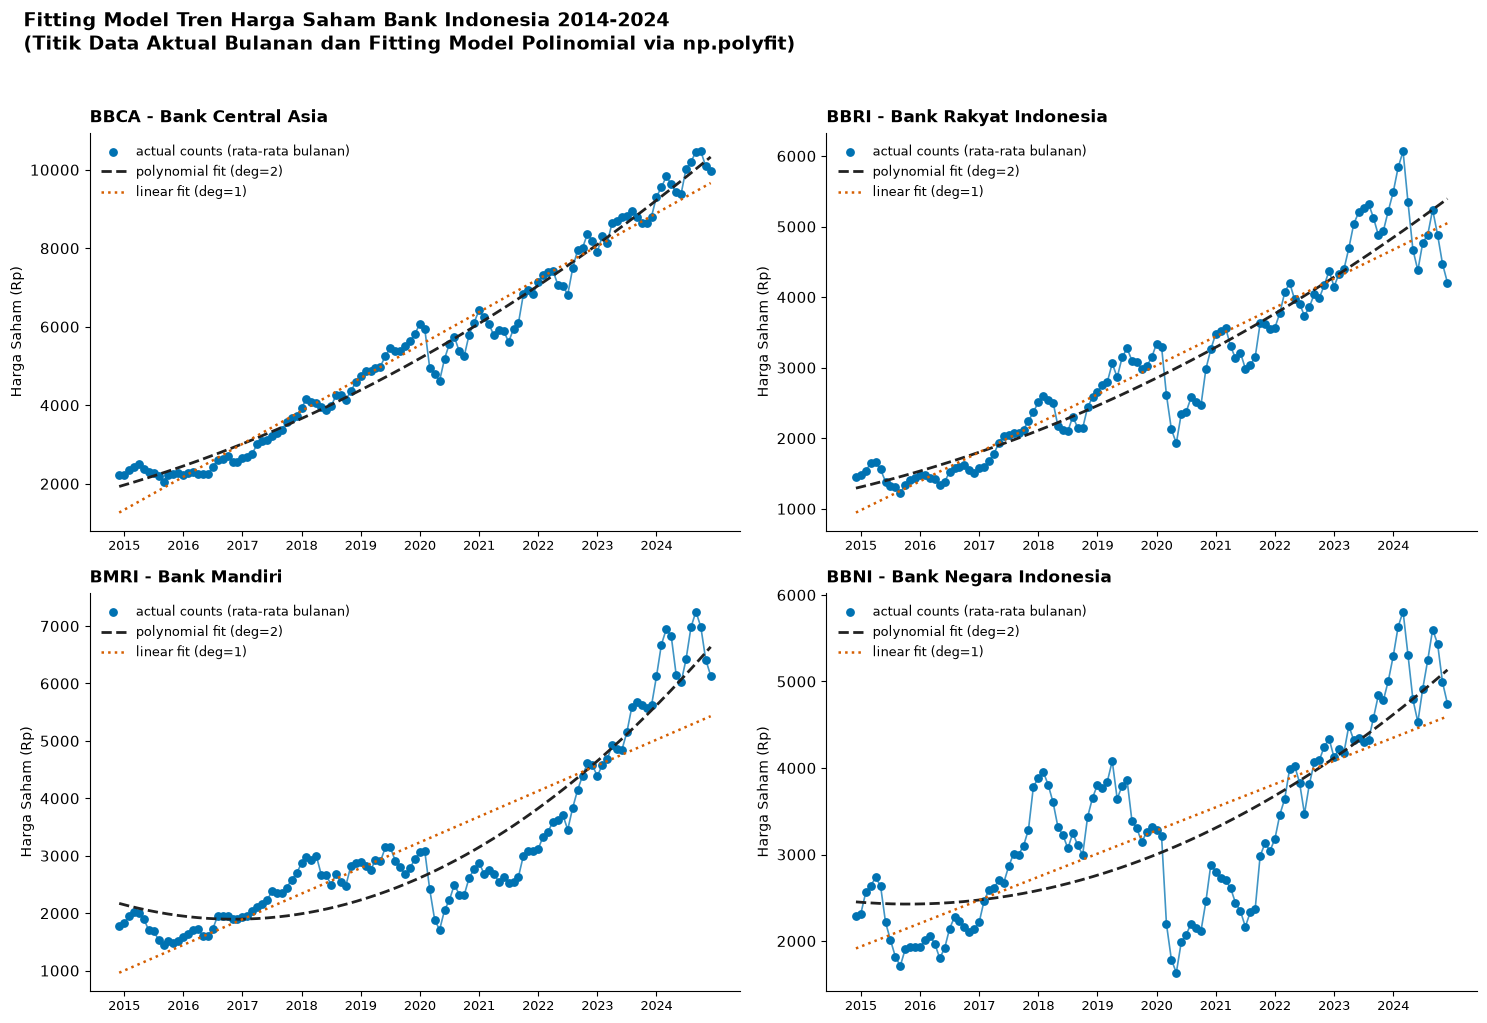

In [14]:
# Resample harga saham ke rata-rata bulanan untuk visualisasi titik bersih
d_bulanan = adj_wide.resample('ME').mean()

# Konversi waktu ke ordinal numerik (bulan ke-n sejak awal observasi)
d_bulan_num = np.arange(len(d_bulanan))
d_x_halus = np.linspace(d_bulan_num[0], d_bulan_num[-1], 300)

# Fitting polinomial linear (deg=1) dan kuadratik (deg=2) per bank
d_koef_lin = {}
d_koef_kua = {}
for ticker in TICKERS:
    y = d_bulanan[ticker].values
    d_koef_lin[ticker] = np.polyfit(d_bulan_num, y, 1)
    d_koef_kua[ticker] = np.polyfit(d_bulan_num, y, 2)

D_C_ACTUAL = '#0072B2'   # biru Okabe-Ito untuk titik dan garis data aktual
D_C_QUAD   = '#222222'   # hitam arang untuk kurva fit kuadratik
D_C_LIN    = '#D55E00'   # oranye vermilion untuk garis fit linear

# Visualisasi
fig, axes = plt.subplots(2, 2, figsize=(15, 10), sharex=False)
axes = axes.flatten()

for idx, ticker in enumerate(TICKERS):
    ax = axes[idx]
    y = d_bulanan[ticker].values
    ax.plot(d_bulan_num, y, color=D_C_ACTUAL, linewidth=1.2, alpha=0.75, zorder=2)
    ax.scatter(d_bulan_num, y, color=D_C_ACTUAL, s=28, zorder=3,
               label='data aktual (rata-rata bulanan)')
    d_tren_kua = np.polyval(d_koef_kua[ticker], d_x_halus)
    ax.plot(d_x_halus, d_tren_kua, color=D_C_QUAD, linewidth=2.0, linestyle='--',
            label='polynomial fit (deg=2)', zorder=4)
    d_tren_lin = np.polyval(d_koef_lin[ticker], d_x_halus)
    ax.plot(d_x_halus, d_tren_lin, color=D_C_LIN, linewidth=1.8, linestyle=':',
            label='linear fit (deg=1)', zorder=4)
    tik_posisi = [i for i, d in enumerate(d_bulanan.index) if d.month == 1]
    tik_label = [d_bulanan.index[i].year for i in tik_posisi]
    ax.set_xticks(tik_posisi)
    ax.set_xticklabels(tik_label, fontsize=9)

    ax.set_title(f'{ticker} - {NAMA_BANK[ticker]}', fontsize=12, fontweight='bold', pad=8)
    ax.set_ylabel('Harga Saham (Rp)', fontsize=10)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(False)
    ax.legend(loc='upper left', fontsize=9, frameon=False)
fig.suptitle(
    'Fitting Model Tren Harga Saham Bank Indonesia 2014-2024\n'
    '(Titik Data Aktual Bulanan dan Fitting Model Polinomial via np.polyfit)',
    fontsize=14, fontweight='bold', x=0.02, ha='left', y=1.02
)
fig.tight_layout()
simpan_fig(fig, '06_fitting_model')
plt.show()

**Insight:** Fit kuadratik menangkap kelengkungan tren lebih baik daripada fit linear, terutama pada BMRI (R² naik dari 0,75 menjadi 0,88). Pada BBCA selisihnya kecil (0,97 menjadi 0,98) karena trennya sudah hampir lurus. BBCA dan BMRI menunjukkan percepatan kenaikan harga setelah 2020 dengan kurva yang melengkung ke atas. BBRI tumbuh kuat hingga 2023 sebelum melandai di 2024, sedangkan BBNI paling sulit dijelaskan oleh kedua model (R² linear 0,57 dan kuadratik 0,62) karena harganya naik-turun dalam rentang yang panjang.

In [15]:
# Ringkasan koefisien regresi model polinomial
def d_r2(ticker, koef):
    y = d_bulanan[ticker].values
    return 1 - ((y - np.polyval(koef, d_bulan_num)) ** 2).sum() / ((y - y.mean()) ** 2).sum()

d_ringkasan = pd.DataFrame({
    'Kemiringan Linear (Rp/bulan)': {t: round(d_koef_lin[t][0], 1) for t in TICKERS},
    'Intersep Linear (Rp)':         {t: round(d_koef_lin[t][1], 0) for t in TICKERS},
    'Koef. Kuadratik a (x^2)':      {t: f"{d_koef_kua[t][0]:.4f}" for t in TICKERS},
    'Koef. Kuadratik b (x)':        {t: f"{d_koef_kua[t][1]:.2f}" for t in TICKERS},
    'R² Linear':                    {t: round(d_r2(t, d_koef_lin[t]), 2) for t in TICKERS},
    'R² Kuadratik':                 {t: round(d_r2(t, d_koef_kua[t]), 2) for t in TICKERS},
})
d_ringkasan.index.name = 'Ticker'
print('Ringkasan Koefisien Model Tren:')
d_ringkasan

Ringkasan Koefisien Model Tren:


,Kemiringan Linear (Rp/bulan),Intersep Linear (Rp),Koef. Kuadratik a (x^2),Koef. Kuadratik b (x)
Ticker,,,,
BBCA,70.0,1266.0,0.2792,36.48
BBRI,34.2,947.0,0.1453,16.74
BMRI,37.2,963.0,0.5073,-23.64
BBNI,22.3,1915.0,0.2260,-4.78


**Insight:** Saham BBCA membukukan kemiringan linear tertinggi (+70,0 Rp/bulan), disusul BMRI (+37,2), BBRI (+34,2), dan BBNI (+22,3). Koefisien kuadratik bernilai positif pada keempat saham, artinya kenaikan harga cenderung semakin cepat sepanjang 2014-2024, dan efek ini paling kuat pada BMRI (0,5073).